# Домашняя работа: TCR-репертуары CD4 и CD8



## 1. Подготовка

In [ ]:
import os
import io
import json
import platform
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image, Markdown
from repseq import clonosets as cl
from repseq import clone_filter as clf
from repseq import stats, beta

aa_table = Path(stats.__file__).resolve().parent / "resourses" / "aa_property_table.txt"
if aa_table.is_file():
    stats.AA_PROPS_PATH = str(aa_table)

if Path("/home/STUDY/FBMF").is_dir() and not os.environ.get("SLURM_JOB_ID"):
    raise RuntimeError("Запустите ядро Jupyter или этот ноутбук внутри задания Slurm.")

CPU = min(2, int(os.environ.get("SLURM_CPUS_PER_TASK", "2")))
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").is_file() and (p / "notebooks").is_dir())
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 110})
GROUPS = ["preterm", "term", "late", "children", "adults", "older_adults"]
PALETTE = dict(zip(GROUPS, sns.color_palette("colorblind", 6)))

def show_figure(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=160, bbox_inches="tight")
    fig.savefig(OUT / f"{name}.pdf", bbox_inches="tight")
    stream = io.BytesIO()
    fig.savefig(stream, format="png", dpi=110, bbox_inches="tight")
    display(Image(data=stream.getvalue()))
    plt.close(fig)

def with_metadata(frame):
    keys = [c for c in ["sample_id", "chain"] if c in frame.columns and c in META.columns]
    columns = list(dict.fromkeys(keys + ["experimental_group", "donor_id", "subset"]))
    result = frame.merge(META[columns], on=keys, how="left", validate="many_to_one")
    result["experimental_group"] = pd.Categorical(result["experimental_group"], GROUPS, ordered=True)
    return result

def group_boxes(frame, properties, labels, name):
    data = with_metadata(frame)
    fig, axes = plt.subplots(1, len(properties), figsize=(5.2 * len(properties), 4.1), squeeze=False)
    for ax, column, label in zip(axes[0], properties, labels):
        sns.boxplot(data=data, x="experimental_group", y=column, order=GROUPS, color="#DAEAF3", showfliers=False, ax=ax)
        sns.stripplot(data=data, x="experimental_group", y=column, order=GROUPS, hue="experimental_group", palette=PALETTE, size=4, jitter=False, legend=False, ax=ax)
        ax.set(xlabel="Группа доноров", ylabel=label)
        ax.tick_params(axis="x", rotation=55)
    fig.suptitle(SUBSET, y=1.03)
    fig.tight_layout()
    show_figure(fig, name)
    return data

def usage_heatmap(frame, segment, name, top=None):
    data = with_metadata(frame)
    wide = data.groupby([segment, "experimental_group"], observed=True)["usage"].mean().unstack(fill_value=0).reindex(columns=GROUPS, fill_value=0)
    if top is not None:
        wide = wide.loc[wide.mean(axis=1).nlargest(top).index]
    wide = wide.sort_index()
    fig, ax = plt.subplots(figsize=(8.6, max(4.8, 0.27 * len(wide))))
    sns.heatmap(wide * 100, cmap="Blues", ax=ax, cbar_kws={"label": "Средняя доля наблюдений, %"})
    ax.set(xlabel="Группа доноров", ylabel=f"{segment.upper()}-ген", title=f"{SUBSET}: использование {segment.upper()}-генов")
    show_figure(fig, name)

print("Python:", platform.python_version())
print("repseq:", version("repseq"))
print("Процессов:", CPU)

Python: 3.12.14
repseq: 0.1.3
Процессов: 2


## 2. Входные данные и состав групп


In [ ]:
candidates = [
    Path(os.environ.get("TCR_DATA_DIR", PROJECT_ROOT / "data" / "ucb_figshare")),
    PROJECT_ROOT.parent / "ImmuneSem" / "data" / "ucb_figshare",
    Path("/home/STUDY/FBMF/bioinformatics/immuno/clonotypes_workshop"),
]
DATA = next((p for p in candidates if (p / "ucb_figshare_TRB_metadata.csv").is_file()), None)
if DATA is None:
    raise FileNotFoundError("Не найдены данные UCB. Распакуйте ImmuneSem рядом с этим проектом или задайте TCR_DATA_DIR.")
META = pd.read_csv(DATA / "ucb_figshare_TRB_metadata.csv")
META["experimental_group"] = pd.Categorical(META["experimental_group"], GROUPS, ordered=True)
FILES = cl.find_all_mixcr_clonosets(str(DATA), chain="TRB", show_offtarget=True)
SAMPLE_DATA = FILES.merge(META.drop(columns="filename"), on=["sample_id", "chain"], validate="one_to_one")
assert not SAMPLE_DATA.duplicated(["donor_id", "subset"]).any()
display(pd.crosstab(SAMPLE_DATA["experimental_group"], SAMPLE_DATA["subset"], dropna=False))
display(SAMPLE_DATA.groupby("subset", observed=True)["UMI_functional"].agg(["count", "min", "median", "max"]))

subset,nCD4,nCD8,nTreg
experimental_group,,,
preterm,3,3,3
term,6,6,6
late,4,4,4
children,4,4,4
adults,9,4,9
older_adults,4,6,4


,count,min,median,max
subset,,,,
nCD4,30,5912,48871.0,254528
nCD8,27,6368,50019.0,193529
nTreg,30,4644,17698.0,125797


## 3. Фильтрация и выбор глубины

Я оставила продуктивные последовательности без стоп-кодонов и сдвигов рамки в CDR3. Для обеих популяций выбрала 5000 наблюдений, а для проверки устойчивости результата повторила альфа-разнообразие при 2500. Согласно метаданным, минимальная функциональная глубина равна 5912 у CD4 и 6368 у CD8, поэтому 5000 позволяет сохранить все образцы. Н

Сохранила `by_umi=True` как в семинаре

In [1]:
DEPTH = 5000
ALT_DEPTH = 2500
SEED = 100
FUNC_FILTER = clf.Filter(functionality="f", by_umi=True)
DOWN_FILTER = clf.Filter(functionality="f", downsample=DEPTH, by_umi=True, seed=SEED)
ALT_FILTER = clf.Filter(functionality="f", downsample=ALT_DEPTH, by_umi=True, seed=SEED)
MC_FILTER = DOWN_FILTER.spawn()
MC_FILTER.seed = None
MC_ALT_FILTER = ALT_FILTER.spawn()
MC_ALT_FILTER.seed = None
RESULTS = {}

NameError: name 'clf' is not defined

## 4. Анализ nCD4

Out[0]: 
            sample_id chain  clones  ...  experimental_group  donor_id  subset
0      c2_mnCD4_TRB_1   TRB    4667  ...            children        c2    nCD4
1     UCB3_nCD4_TRB_1   TRB   38736  ...                term      UCB3    nCD4
2     UCB9_nCD4_TRB_2   TRB  115560  ...                late      UCB9    nCD4
3    UCB10_nCD4_TRB_1   TRB  125688  ...                term     UCB10    nCD4
4     UCB2_nCD4_TRB_1   TRB   81956  ...                term      UCB2    nCD4
5      c5_mnCD4_TRB_1   TRB   26673  ...            children        c5    nCD4
6      a9_mnCD4_TRB_1   TRB   24536  ...              adults        a9    nCD4
7     UCB5_nCD4_TRB_2   TRB   49366  ...             preterm      UCB5    nCD4
8     a10_mnCD4_TRB_1   TRB   42295  ...              adults       a10    nCD4
9   UCB13_mnCD4_TRB_1   TRB   32131  ...                term     UCB13    nCD4
10   UCB11_nCD4_TRB_1   TRB   64477  ...             preterm     UCB11    nCD4
11    UCB6_nCD4_TRB_1   TRB   23056  ...   

,Число образцов
experimental_group,
preterm,3
term,6
late,4
children,4
adults,9
older_adults,4


,sample_id,clones_func,reads_func
0,c2_mnCD4_TRB_1,4508,5912
21,c4_mnCD4_TRB_1,9515,13695
22,a7_mnCD4_TRB_1,14760,22220
29,UCB4_nCD4_TRB_1,14235,23395
5,c5_mnCD4_TRB_1,25952,32077
11,UCB6_nCD4_TRB_1,22069,33053
18,UCB12_mnCD4_TRB_1,27005,33459
6,a9_mnCD4_TRB_1,23743,35572
19,o5_mnCD4_TRB_1,17835,35797
20,a1_mnCD4_TRB_1,25444,38486


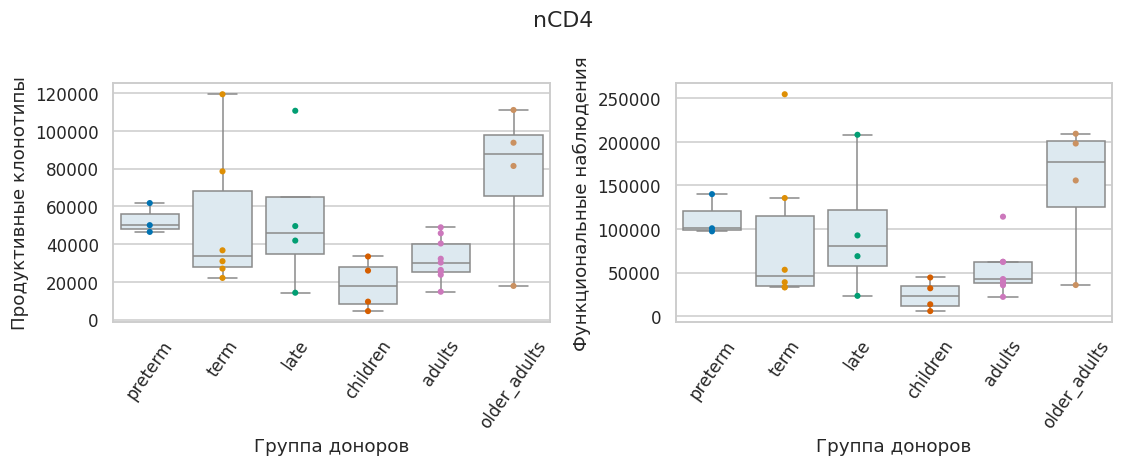

In [ ]:
SUBSET = "nCD4"
SAMPLES = SAMPLE_DATA.loc[SAMPLE_DATA["subset"].eq(SUBSET)].copy().reset_index(drop=True)
OUT = PROJECT_ROOT / "outputs" / "tcr" / SUBSET
OUT.mkdir(parents=True, exist_ok=True)
display(SAMPLES.groupby("experimental_group", observed=True).size().rename("Число образцов").to_frame())
clonoset_stats = stats.calc_clonoset_stats(SAMPLES, cpu=CPU, verbose=False)
assert clonoset_stats["reads_func"].ge(DEPTH).all()
clonoset_stats.to_csv(OUT / "clonoset_stats.csv", index=False)
display(clonoset_stats[["sample_id", "clones_func", "reads_func"]].sort_values("reads_func"))
group_boxes(clonoset_stats, ["clones_func", "reads_func"], ["Продуктивные клонотипы", "Функциональные наблюдения"], "01_depth")

### CDR3: длины, вставки и аминокислотные свойства

Это частотно-взвешенные характеристики продуктивных клонотипов до даунсэмплинга, как в семинаре. На распределении длин сначала считала долю наблюдений каждой длины для каждого образца, затем усредняла по донорам внутри группы, поэтому глубокие образцы не получают больший вес.

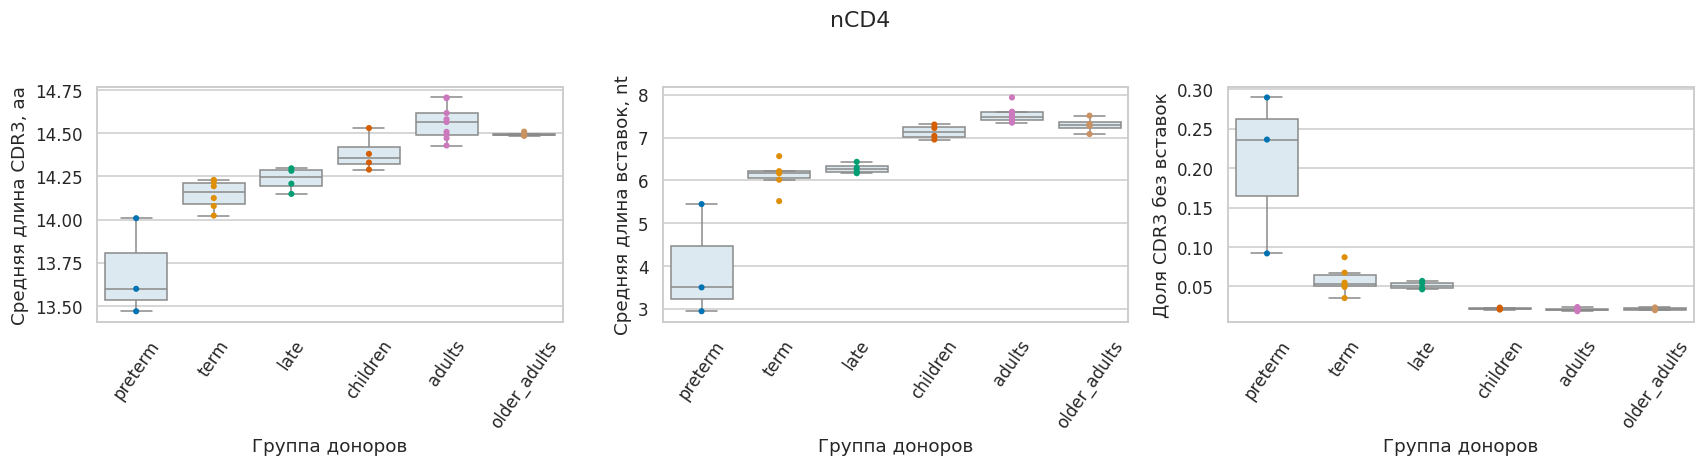

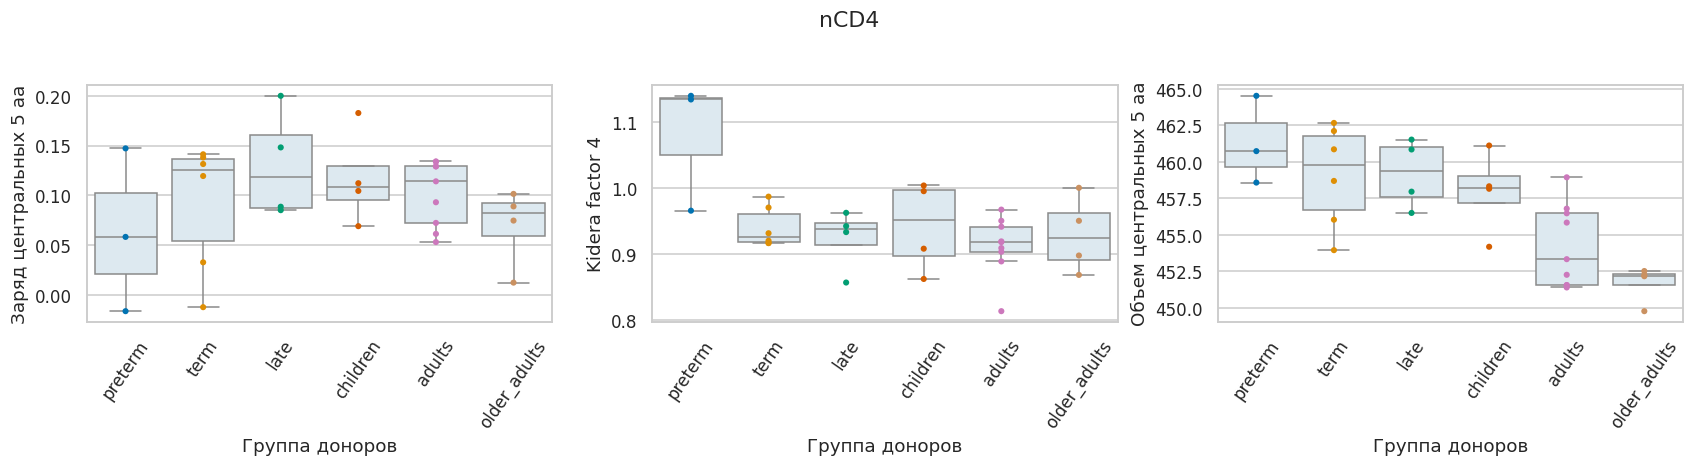

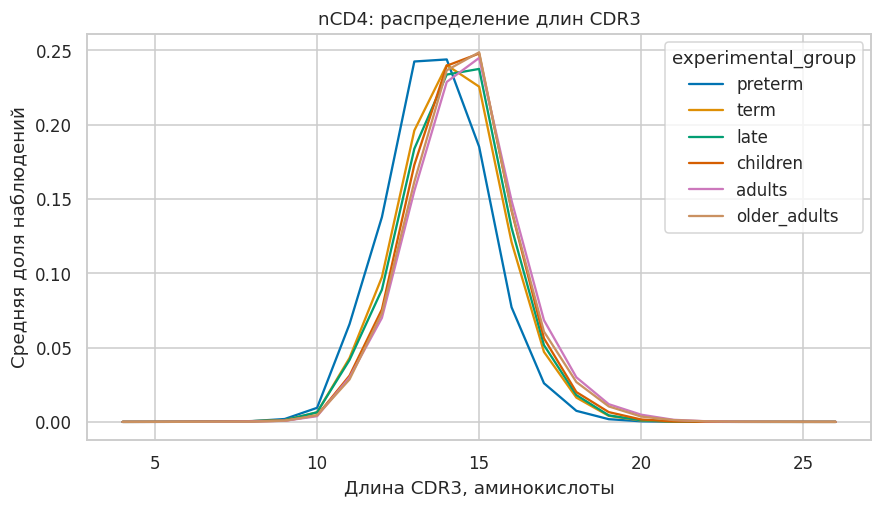

,mean_cdr3aa_len,mean_insert_size,zero_insert_freq
experimental_group,,,
preterm,13.5990,3.4977,0.2362
term,14.1588,6.1780,0.0532
late,14.2450,6.2539,0.0509
children,14.3553,7.1318,0.0216
adults,14.5646,7.4804,0.0204
older_adults,14.4876,7.2964,0.0213


In [ ]:
cdr3_properties = stats.calc_cdr3_properties(SAMPLES, cl_filter=FUNC_FILTER, cpu=CPU, verbose=False)
cdr3_properties["mean_cdr3aa_len"] = cdr3_properties["mean_cdr3nt_len"] / 3
cdr3_properties.to_csv(OUT / "cdr3_properties.csv", index=False)
group_boxes(cdr3_properties, ["mean_cdr3aa_len", "mean_insert_size", "zero_insert_freq"], ["Средняя длина CDR3, aa", "Средняя длина вставок, nt", "Доля CDR3 без вставок"], "02_cdr3_properties")
group_boxes(cdr3_properties, ["cdr3_5_charge", "cdr3_5_kf4", "cdr3_5_volume"], ["Заряд центральных 5 aa", "Kidera factor 4", "Объем центральных 5 aa"], "03_amino_acid_properties")
lengths = stats.cdr3_length_distributions(SAMPLES, cl_filter=FUNC_FILTER, cpu=CPU, count_by_freq=True, seq_type="aa", zero_fill=True, verbose=False)
lengths.to_csv(OUT / "cdr3_lengths.csv", index=False)
lengths_meta = with_metadata(lengths)
length_means = lengths_meta.groupby(["experimental_group", "cdr3_length"], observed=True)["freq"].mean().reset_index()
fig, ax = plt.subplots(figsize=(9.2, 4.8))
sns.lineplot(data=length_means, x="cdr3_length", y="freq", hue="experimental_group", hue_order=GROUPS, palette=PALETTE, ax=ax)
ax.set(xlabel="Длина CDR3, аминокислоты", ylabel="Средняя доля наблюдений", title=f"{SUBSET}: распределение длин CDR3")
show_figure(fig, "04_cdr3_length_distribution")
display(with_metadata(cdr3_properties).groupby("experimental_group", observed=True)[["mean_cdr3aa_len", "mean_insert_size", "zero_insert_freq"]].median().round(4))

### Использование V- и J-генов

Считала частоты сегментов в продуктивной части каждого репертуара. Для V показала 20 наиболее используемых генов по средней частоте, полная таблица всех V-генов сохраняется в CSV. J-гены показаны полностью. Частоты сначала считаются для каждого донора, затем усредняются по группе.

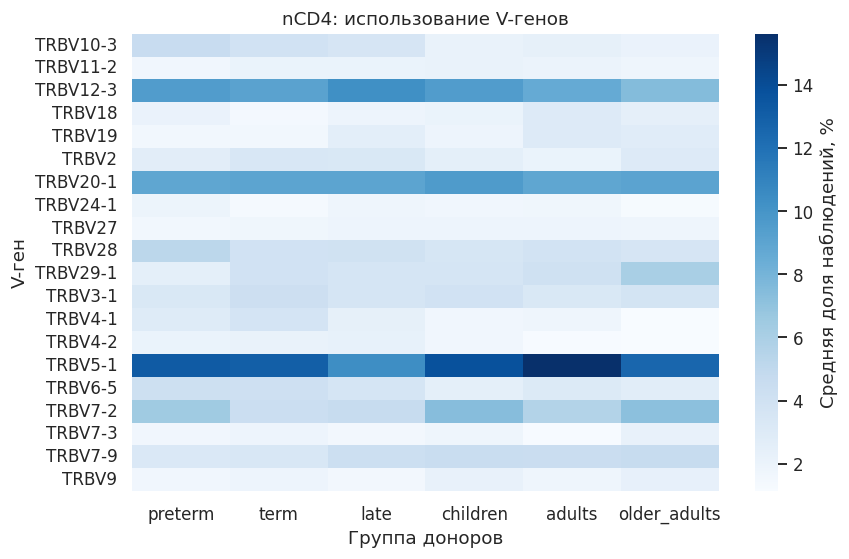

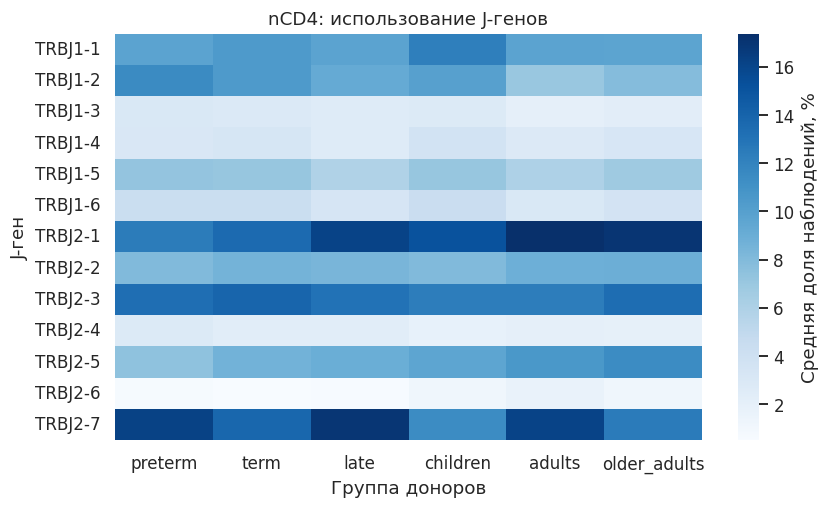

In [ ]:
v_usage = stats.calc_segment_usage(SAMPLES, segment="v", cl_filter=FUNC_FILTER, cpu=CPU, verbose=False)
j_usage = stats.calc_segment_usage(SAMPLES, segment="j", cl_filter=FUNC_FILTER, cpu=CPU, verbose=False)
v_usage.to_csv(OUT / "v_usage.csv", index=False)
j_usage.to_csv(OUT / "j_usage.csv", index=False)
usage_heatmap(v_usage, "v", "05_v_usage_top20", top=20)
usage_heatmap(j_usage, "j", "06_j_usage")

### Конвергенция

Метрика показывает, сколько разных нуклеотидных CDR3 в среднем соответствует одной аминокислотной CDR3. Отдельно учитываются совпадения с тем же V-геном и с теми же V/J. Для сравнения использую равную глубину 5000. Более высокое значение согласуется с более выраженной конвергентной рекомбинацией, но не доказывает общую антигенную специфичность.

Calcultating stats for original clonosets
_________________________________________
WARNING! Following samples have NaN downsample counts ('umi_func'): c2_mnCD4_TRB_1, UCB3_nCD4_TRB_1, UCB9_nCD4_TRB_2, UCB10_nCD4_TRB_1, UCB2_nCD4_TRB_1, c5_mnCD4_TRB_1, a9_mnCD4_TRB_1, UCB5_nCD4_TRB_2, a10_mnCD4_TRB_1, UCB13_mnCD4_TRB_1, UCB11_nCD4_TRB_1, UCB6_nCD4_TRB_1, a5_mnCD4_TRB_1, o1_mnCD4_TRB_1, c1_mnCD4_TRB_1, UCB1_nCD4_TRB_2, UCB8_nCD4_TRB_1, UCB7_nCD4_TRB_1, UCB12_mnCD4_TRB_1, o5_mnCD4_TRB_1, a1_mnCD4_TRB_1, c4_mnCD4_TRB_1, a7_mnCD4_TRB_1, a13_mnCD4_TRB_1, o3_mnCD4_TRB_2, a11_mnCD4_TRB_1, a15_mnCD4_TRB_1, o6_mnCD4_TRB_2, a3_mnCD4_TRB_1, UCB4_nCD4_TRB_1
These samples will be counted by reads instead
Out[0]: 
            sample_id chain  convergence  ...  experimental_group  donor_id subset
0      c2_mnCD4_TRB_1   TRB     1.001770  ...            children        c2   nCD4
1     UCB3_nCD4_TRB_1   TRB     1.011217  ...                term      UCB3   nCD4
2     UCB9_nCD4_TRB_2   TRB     1.005829 

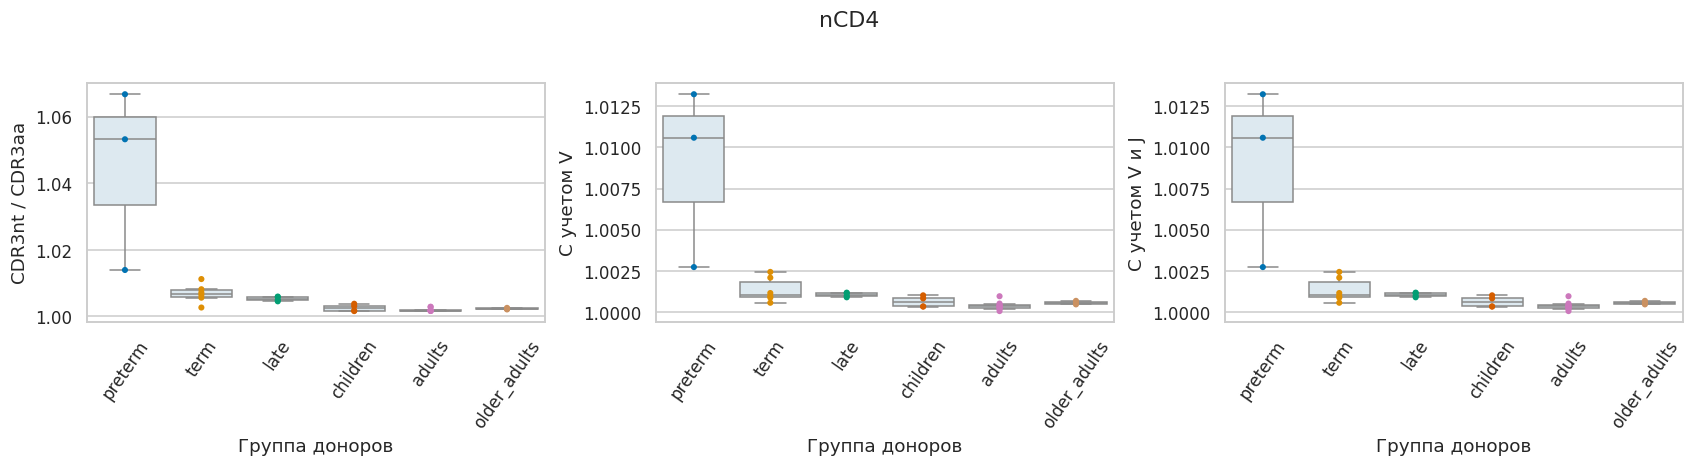

In [ ]:
convergence = stats.calc_convergence(SAMPLES, cl_filter=MC_FILTER, seed=42, iterations=3, cpu=CPU, verbose=False)
convergence.to_csv(OUT / "convergence.csv", index=False)
group_boxes(convergence, ["convergence", "convergence_v", "convergence_vj"], ["CDR3nt / CDR3aa", "С учетом V", "С учетом V и J"], "07_convergence")

### Альфа-разнообразие и чувствительность к глубине

`diversity` - число наблюдаемых клонотипов, Shannon учитывает богатство и равномерность, `clonality = 1 - нормированный Shannon`. Chao1 оценивает богатство с учетом редких клонотипов и может быть нестабильным. Выполняю три воспроизводимых повтора субсэмплирования; в таблицах показаны их средние значения. Для повторов seed задается в функции расчета, а seed внутри копии фильтра отключен: иначе эта версия repseq заново фиксирует одну и ту же выборку на каждом повторе.

Calcultating stats for original clonosets
_________________________________________
WARNING! Following samples have NaN downsample counts ('umi_func'): c2_mnCD4_TRB_1, UCB3_nCD4_TRB_1, UCB9_nCD4_TRB_2, UCB10_nCD4_TRB_1, UCB2_nCD4_TRB_1, c5_mnCD4_TRB_1, a9_mnCD4_TRB_1, UCB5_nCD4_TRB_2, a10_mnCD4_TRB_1, UCB13_mnCD4_TRB_1, UCB11_nCD4_TRB_1, UCB6_nCD4_TRB_1, a5_mnCD4_TRB_1, o1_mnCD4_TRB_1, c1_mnCD4_TRB_1, UCB1_nCD4_TRB_2, UCB8_nCD4_TRB_1, UCB7_nCD4_TRB_1, UCB12_mnCD4_TRB_1, o5_mnCD4_TRB_1, a1_mnCD4_TRB_1, c4_mnCD4_TRB_1, a7_mnCD4_TRB_1, a13_mnCD4_TRB_1, o3_mnCD4_TRB_2, a11_mnCD4_TRB_1, a15_mnCD4_TRB_1, o6_mnCD4_TRB_2, a3_mnCD4_TRB_1, UCB4_nCD4_TRB_1
These samples will be counted by reads instead
Calcultating stats for original clonosets
_________________________________________
WARNING! Following samples have NaN downsample counts ('umi_func'): c2_mnCD4_TRB_1, UCB3_nCD4_TRB_1, UCB9_nCD4_TRB_2, UCB10_nCD4_TRB_1, UCB2_nCD4_TRB_1, c5_mnCD4_TRB_1, a9_mnCD4_TRB_1, UCB5_nCD4_TRB_2, a10_mnCD4_TRB

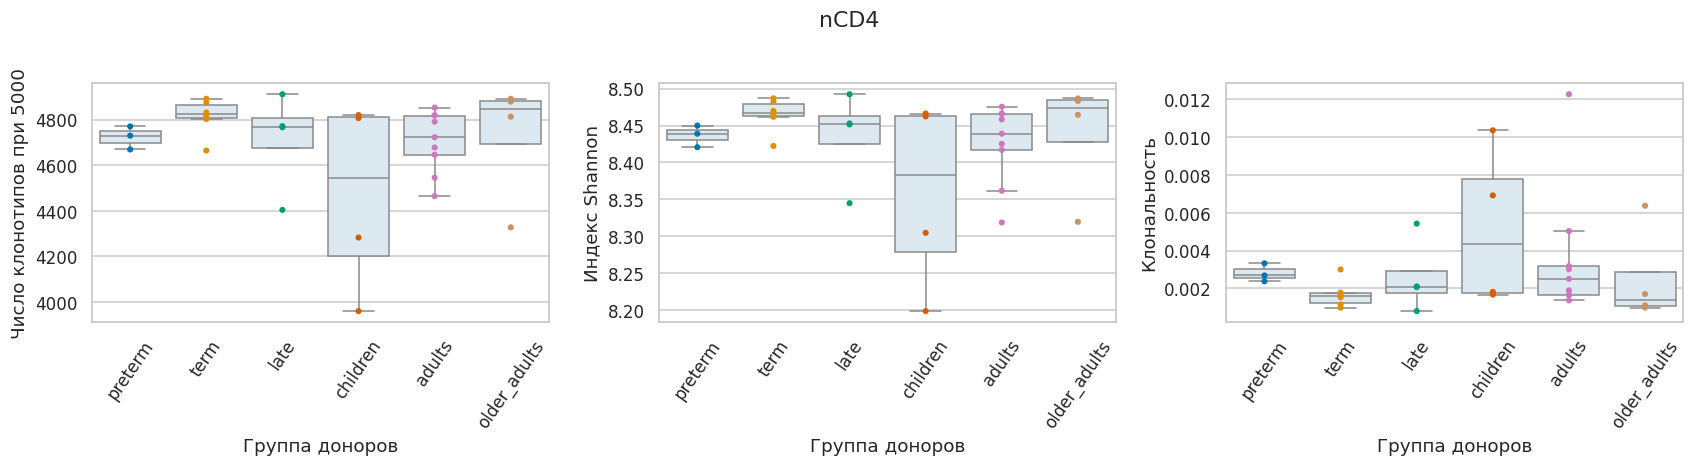

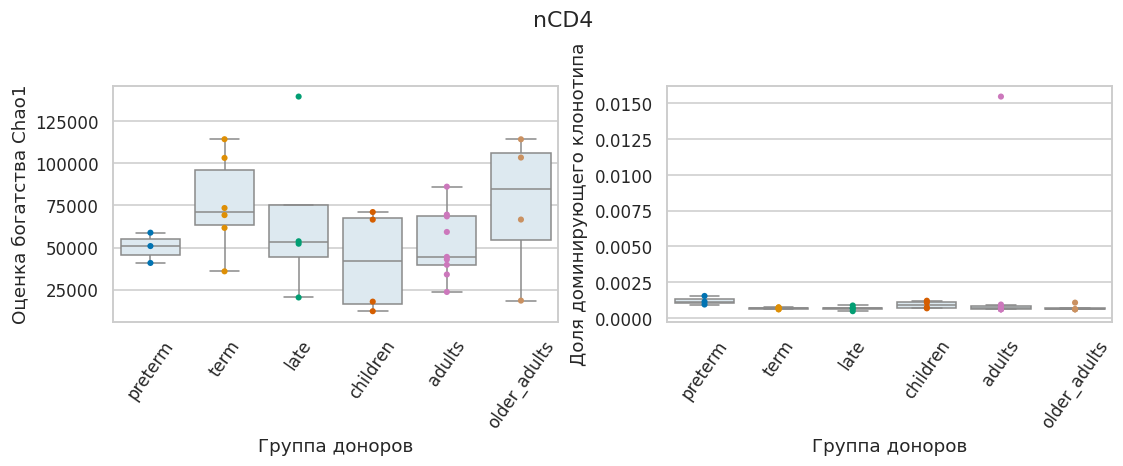

,diversity,shannon_wiener,clonality,chao1,berger_parker
experimental_group,,,,,
preterm,4729.6667,8.4389,0.0027,50895.8241,0.0011
term,4823.8333,8.4676,0.0016,71391.1415,0.0007
late,4768.8333,8.4522,0.0021,53011.4590,0.0007
children,4544.6667,8.3834,0.0044,42230.7824,0.0009
adults,4722.6667,8.4389,0.0025,44457.4423,0.0007
older_adults,4845.8333,8.4739,0.0014,85062.9877,0.0006


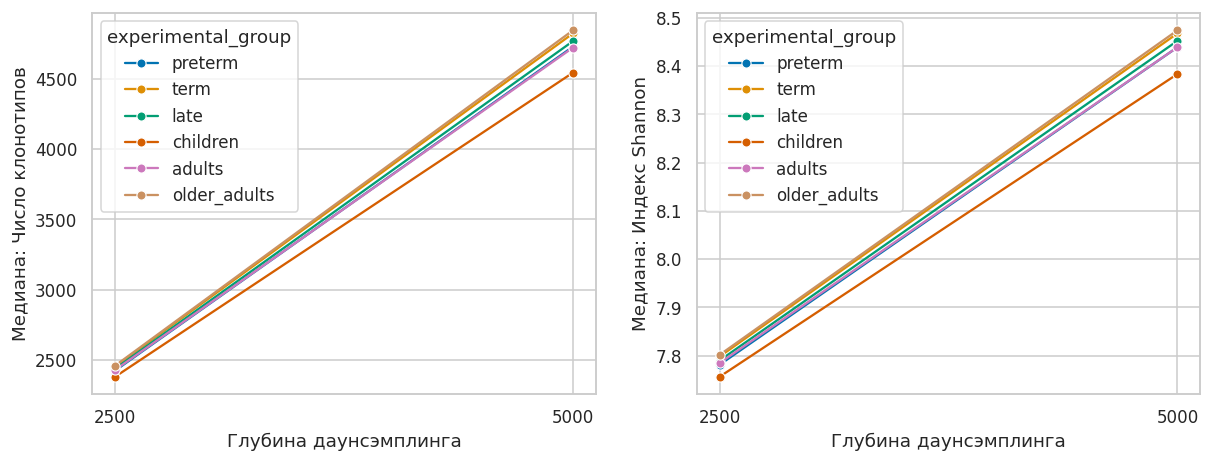

,Метрика,Корреляция рангов между глубинами
0,diversity,0.991655
1,shannon_wiener,0.992546
2,clonality,0.989766


In [ ]:
diversity = stats.calc_diversity_stats(SAMPLES, cl_filter=MC_FILTER, seed=123, iterations=3, drop_small_samples=False, cpu=CPU, verbose=False)
diversity_alt = stats.calc_diversity_stats(SAMPLES, cl_filter=MC_ALT_FILTER, seed=123, iterations=3, drop_small_samples=False, cpu=CPU, verbose=False)
diversity.to_csv(OUT / "diversity_5000.csv", index=False)
diversity_alt.to_csv(OUT / "diversity_2500.csv", index=False)
group_boxes(diversity, ["diversity", "shannon_wiener", "clonality"], ["Число клонотипов при 5000", "Индекс Shannon", "Клональность"], "08_alpha_diversity")
group_boxes(diversity, ["chao1", "berger_parker"], ["Оценка богатства Chao1", "Доля доминирующего клонотипа"], "09_chao1_dominance")
summary = with_metadata(diversity).groupby("experimental_group", observed=True)[["diversity", "shannon_wiener", "clonality", "chao1", "berger_parker"]].median()
display(summary.round(4))
sensitivity = pd.concat([with_metadata(diversity).assign(depth=DEPTH), with_metadata(diversity_alt).assign(depth=ALT_DEPTH)], ignore_index=True)
sensitivity.to_csv(OUT / "sensitivity.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric, label in zip(axes, ["diversity", "shannon_wiener"], ["Число клонотипов", "Индекс Shannon"]):
    grouped = sensitivity.groupby(["experimental_group", "depth"], observed=True)[metric].median().reset_index()
    sns.lineplot(data=grouped, x="depth", y=metric, hue="experimental_group", hue_order=GROUPS, marker="o", palette=PALETTE, ax=ax)
    ax.set(xlabel="Глубина даунсэмплинга", ylabel=f"Медиана: {label}", xticks=[ALT_DEPTH, DEPTH])
show_figure(fig, "10_sensitivity")
stability = diversity[["sample_id", "diversity", "shannon_wiener", "clonality"]].merge(diversity_alt[["sample_id", "diversity", "shannon_wiener", "clonality"]], on="sample_id", suffixes=("_5000", "_2500"), validate="one_to_one")
display(pd.DataFrame({"Метрика": ["diversity", "shannon_wiener", "clonality"], "Корреляция рангов между глубинами": [stability[f"{m}_5000"].corr(stability[f"{m}_2500"], method="spearman") for m in ["diversity", "shannon_wiener", "clonality"]]}))

### Rarefaction

Кривая показывает, сколько разных клонотипов ожидается при заданном числе наблюдений. Растущая кривая без плато означает неполное покрытие репертуара. Образцы сравниваются при одной и той же глубине, а не по конечным точкам кривых разной длины.

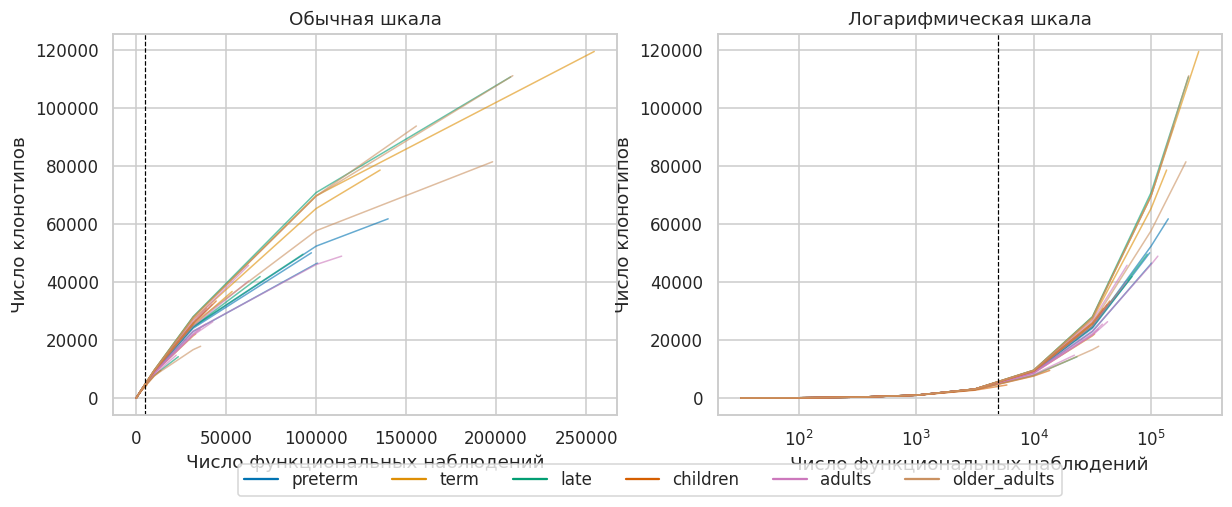

In [ ]:
rarefaction = stats.calc_rarefaction_curve(SAMPLES, cl_filter=FUNC_FILTER, seed=100, iterations=3, cpu=CPU, verbose=False)
rarefaction.to_csv(OUT / "rarefaction.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, log in zip(axes, [False, True]):
    for sample_id, frame in with_metadata(rarefaction).groupby("sample_id", observed=True):
        group = str(frame["experimental_group"].iloc[0])
        frame = frame.sort_values("rarefaction_depth")
        ax.plot(frame["rarefaction_depth"], frame["diversity"], color=PALETTE[group], alpha=0.6, linewidth=1)
    if log:
        ax.set_xscale("log")
    ax.axvline(DEPTH, color="black", ls="--", lw=0.8)
    ax.set(xlabel="Число функциональных наблюдений", ylabel="Число клонотипов", title="Логарифмическая шкала" if log else "Обычная шкала")
handles = [matplotlib.lines.Line2D([0], [0], color=PALETTE[g], label=g) for g in GROUPS]
fig.legend(handles=handles, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.07))
show_figure(fig, "11_rarefaction")

### Бета-разнообразие: F2 и MDS

Совпадение определяется по CDR3aa и V-гену (`aaV`). F2 - сходство с учетом частот, а не расстояние. Отдельно вычисляю F2 для каждой клеточной популяции. Координаты MDS условные, расстояния между точками отражают преобразованное сходство. Видимая группировка без статистической проверки не означает значимость. Попарные сравнения не являются независимыми наблюдениями.

Intersecting clones in clonosets
--------------------------------------------------
Overlap type: aaV
Reading clonosets |##################################################| 30/30 sample(s) processed
Using 2 cores
Intersecting clonosets |##################################################| 435/435 pairs processed


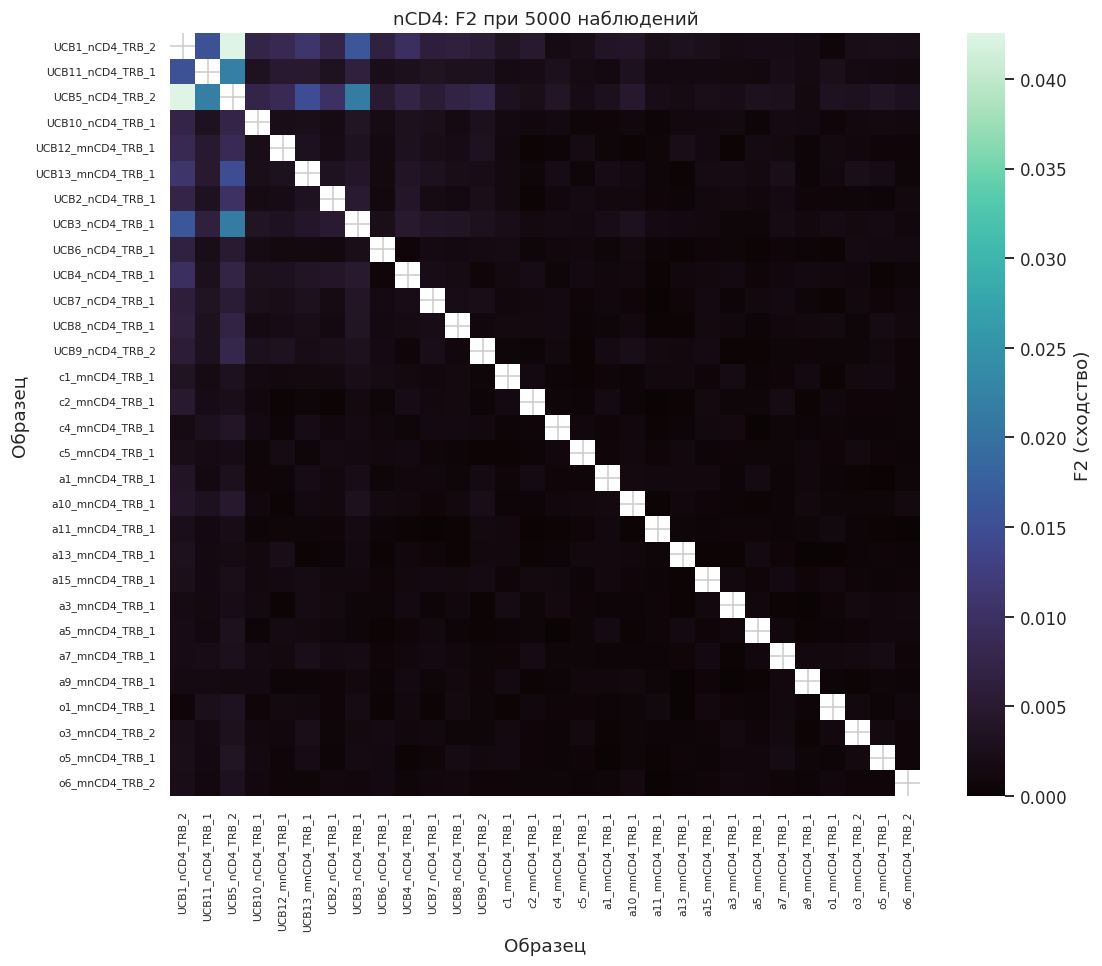

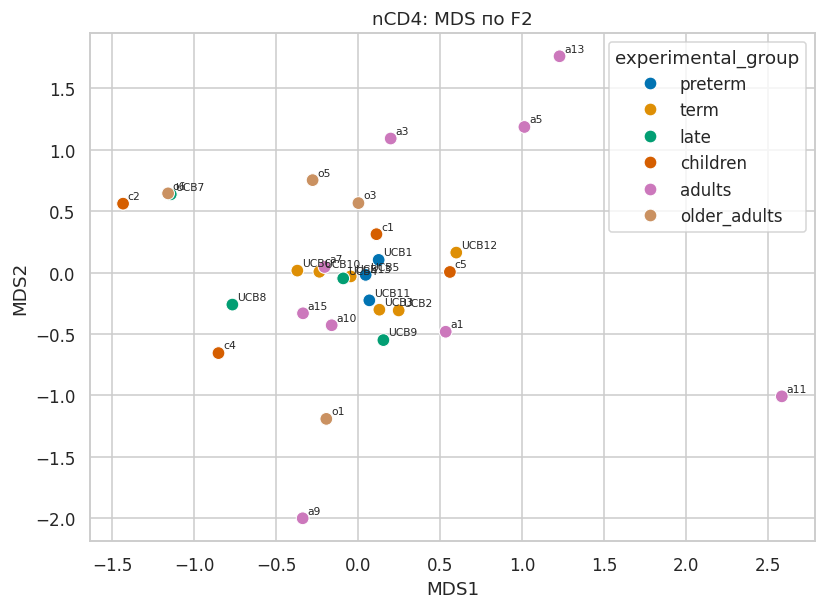

,count,median
group1,,
preterm,3,0.02192
term,15,0.00240
late,6,0.00189
children,6,0.00064
adults,36,0.00071
older_adults,6,0.00084


In [ ]:
f2 = beta.metrics(SAMPLES, cl_filter=DOWN_FILTER, overlap_type="aaV", metrics="f2", cpu=CPU)
f2.to_csv(OUT / "f2.csv")
assert np.allclose(f2.to_numpy(), f2.to_numpy().T)
assert np.allclose(np.diag(f2), 1)
sample_order = SAMPLES.sort_values(["experimental_group", "donor_id"])["sample_id"].tolist()
fig, ax = plt.subplots(figsize=(11, 9))
mask = np.eye(len(f2), dtype=bool)
sns.heatmap(f2.loc[sample_order, sample_order], mask=mask, cmap="mako", ax=ax, cbar_kws={"label": "F2 (сходство)"})
ax.set(title=f"{SUBSET}: F2 при 5000 наблюдений", xlabel="Образец", ylabel="Образец")
ax.tick_params(labelsize=7)
show_figure(fig, "12_f2_heatmap")
mds = beta.mds(f2)
mds.to_csv(OUT / "mds.csv", index=False)
mds_meta = with_metadata(mds)
fig, ax = plt.subplots(figsize=(8.5, 6))
sns.scatterplot(data=mds_meta, x="MDS1", y="MDS2", hue="experimental_group", hue_order=GROUPS, palette=PALETTE, s=70, ax=ax)
for row in mds_meta.itertuples():
    ax.annotate(row.sample_id.split("_")[0], (row.MDS1, row.MDS2), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(title=f"{SUBSET}: MDS по F2")
show_figure(fig, "13_mds")
pairs = []
groups_by_sample = SAMPLES.set_index("sample_id")["experimental_group"].astype(str)
for i, first in enumerate(f2.index):
    for second in f2.index[i + 1:]:
        group1, group2 = groups_by_sample[first], groups_by_sample[second]
        pairs.append({"sample1": first, "sample2": second, "group1": group1, "group2": group2, "f2": f2.loc[first, second], "same_group": group1 == group2})
pair_table = pd.DataFrame(pairs)
pair_table.to_csv(OUT / "f2_pairs.csv", index=False)
display(pair_table.loc[pair_table["same_group"]].groupby("group1")["f2"].agg(["count", "median"]).reindex(GROUPS).round(5))
RESULTS[SUBSET] = {"clonoset_stats": clonoset_stats, "cdr3_properties": cdr3_properties, "diversity": diversity, "diversity_alt": diversity_alt, "convergence": convergence, "f2": f2, "mds": mds}

### Интерпретация nCD4

Для nCD4 проанализировано 30 образцов из шести групп. Минимальная функциональная глубина равна 5912, поэтому даунсэмплирование до 5000 сохранило все образцы. Подсчитанные размеры продуктивных клоносетов и наблюдений совпали с метаданными архива.

У недоношенных детей медиана средней длины CDR3 составила 13,60 aa, а у взрослых - 14,56 aa. Медиана средней длины вставок составила 3,50 и 7,48 nt соответственно. Доля CDR3 без вставок у недоношенных была 23,62%, у взрослых - 2,04%. Таким образом, ранние репертуары содержат более короткие CDR3 с меньшим количеством вставок. Это повторяет основное наблюдение семинара для другой клеточной популяции.

Для пяти центральных аминокислот CDR3 медианы показателя заряда составили 0,058 у недоношенных и 0,114 у взрослых; KF4 - 1,134 и 0,918, показателя объема - 460,7 и 453,3. Это характеристики аминокислотного состава в шкалах repseq. По ним нельзя определять заряд целого рецептора, силу связывания или антигенную специфичность. Анализ фиксированного центрального участка уменьшает прямое влияние различной длины CDR3.

Среди наиболее используемых V-генов в среднем по всем образцам - TRBV5-1, TRBV20-1, TRBV12-3; среди J-генов - TRBJ2-1, TRBJ2-7. На heatmap видны различия профилей между группами. При этом наиболее частый ген сам по себе не является доказательством специфического ответа на определенный антиген. Чтобы говорить о значимости отдельных различий V/J, нужна отдельная статистическая проверка с учетом множественных сравнений.

При одинаковой глубине 5000 медиана числа клонотипов у недоношенных составила 4729,7, у взрослых - 4722,7, у пожилых - 4845,8. Медианы Shannon в этих группах равны 8,439, 8,439 и 8,474. Разнообразие не следует трактовать как автоматически и строго монотонную функцию возраста: смотрю на все группы и разброс отдельных доноров.

В CD4 медианы Shannon и клональности близки между группами; устойчивого снижения разнообразия от младших групп к старшим здесь не видно.

Корреляция рангов образцов между глубинами 2500 и 5000 составила 0,992 для числа клонотипов и 0,993 для Shannon. При меньшей глубине ожидаемо обнаруживается меньше разных клонотипов. Эти корреляции показывают устойчивость ранжирования к выбранным двум глубинам, но не заменяют проверку биологических гипотез и не подтверждают устойчивость при любых настройках.

Конвергенция CDR3aa у недоношенных имела групповую медиану 1,0532, у взрослых - 1,0018. Она описывает соотношение разных нуклеотидных и аминокислотных вариантов, а не число B/T-клеточных линий происхождения.

На последнем участке rarefaction медианный прирост составил 0,468 нового клонотипа на одно дополнительное наблюдение. Кривые продолжают расти; полного насыщения секвенированием не достигнуто. Поэтому число найденных клонотипов не равно всему разнообразию, присутствующему у донора.

Наибольшая медиана внутригруппового F2 получилась в группе preterm: 0,02192. Для preterm она составила 0,02192, для adults - 0,00071. Это описательная характеристика сходства по aaV. Более высокое сходство ранних репертуаров согласуется с большей долей повторяющихся вариантов CDR3, но само по себе не устанавливает механизм их образования. Внутригрупповые пары не независимы, поэтому их количество нельзя использовать как число биологических повторов. На MDS образцы пуповинной крови располагаются сравнительно близко, а среди более старших доноров есть удаленные точки; полного разделения всех возрастных групп нет. MDS носит описательный характер. Нельзя приписывать отдельному кластеру общую антигенную специфичность по одному только расположению на графике.

## 5. Анализ nCD8

Out[0]: 
           sample_id chain  clones  ...  experimental_group  donor_id  subset
0      o3_nCD8_TRB_1   TRB    5635  ...        older_adults        o3    nCD8
1   UCB13_nCD8_TRB_1   TRB   42841  ...                term     UCB13    nCD8
2      o1_nCD8_TRB_1   TRB   35822  ...        older_adults        o1    nCD8
3      a5_nCD8_TRB_1   TRB   15111  ...              adults        a5    nCD8
4    UCB4_nCD8_TRB_1   TRB   15945  ...                late      UCB4    nCD8
5   UCB12_nCD8_TRB_1   TRB   20368  ...                term     UCB12    nCD8
6      o2_nCD8_TRB_1   TRB    7077  ...        older_adults        o2    nCD8
7    UCB7_nCD8_TRB_1   TRB   16440  ...                late      UCB7    nCD8
8     a12_nCD8_TRB_1   TRB   20752  ...              adults       a12    nCD8
9    UCB8_nCD8_TRB_1   TRB   35689  ...                late      UCB8    nCD8
10     a4_nCD8_TRB_1   TRB   45378  ...              adults        a4    nCD8
11  UCB11_nCD8_TRB_1   TRB   69412  ...             pre

,Число образцов
experimental_group,
preterm,3
term,6
late,4
children,4
adults,4
older_adults,6


,sample_id,clones_func,reads_func
23,o7_nCD8_TRB_1,5823,6368
6,o2_nCD8_TRB_1,6818,8056
0,o3_nCD8_TRB_1,5332,8941
18,o4_nCD8_TRB_1,4931,12500
3,a5_nCD8_TRB_1,14377,16091
7,UCB7_nCD8_TRB_1,15764,19100
22,a6_nCD8_TRB_1,19070,20571
8,a12_nCD8_TRB_1,20166,21375
5,UCB12_nCD8_TRB_1,19465,23304
4,UCB4_nCD8_TRB_1,15199,27005


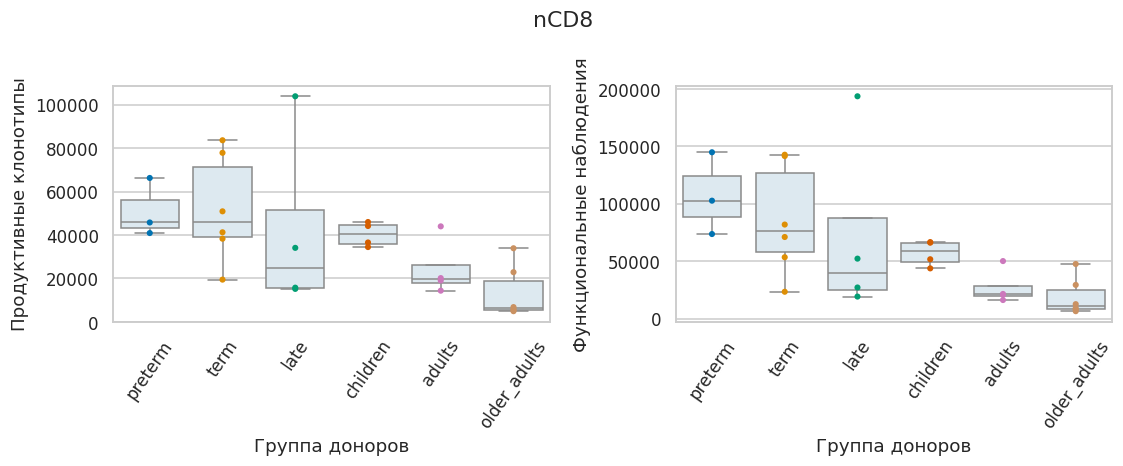

In [ ]:
SUBSET = "nCD8"
SAMPLES = SAMPLE_DATA.loc[SAMPLE_DATA["subset"].eq(SUBSET)].copy().reset_index(drop=True)
OUT = PROJECT_ROOT / "outputs" / "tcr" / SUBSET
OUT.mkdir(parents=True, exist_ok=True)
display(SAMPLES.groupby("experimental_group", observed=True).size().rename("Число образцов").to_frame())
clonoset_stats = stats.calc_clonoset_stats(SAMPLES, cpu=CPU, verbose=False)
assert clonoset_stats["reads_func"].ge(DEPTH).all()
clonoset_stats.to_csv(OUT / "clonoset_stats.csv", index=False)
display(clonoset_stats[["sample_id", "clones_func", "reads_func"]].sort_values("reads_func"))
group_boxes(clonoset_stats, ["clones_func", "reads_func"], ["Продуктивные клонотипы", "Функциональные наблюдения"], "01_depth")

### CDR3: длины, вставки и аминокислотные свойства

Это частотно-взвешенные характеристики продуктивных клонотипов до даунсэмплинга, как в семинаре. На распределении длин сначала считаю долю наблюдений каждой длины для каждого образца, затем усредняю по донорам внутри группы. Поэтому глубокие образцы не получают больший вес.

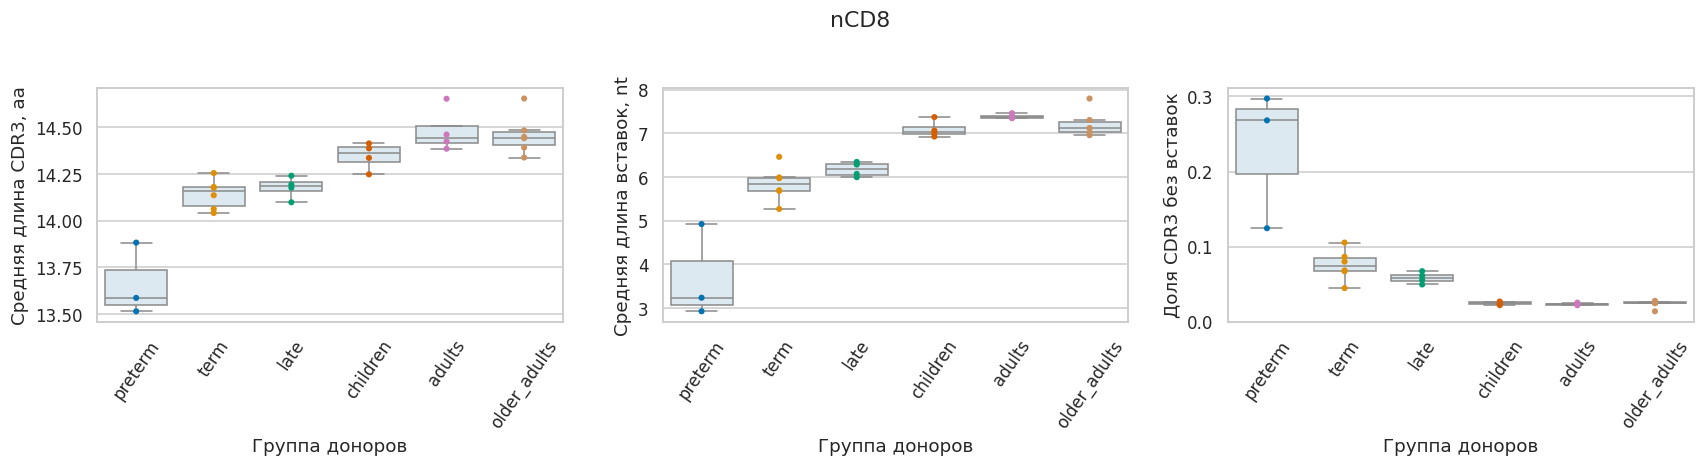

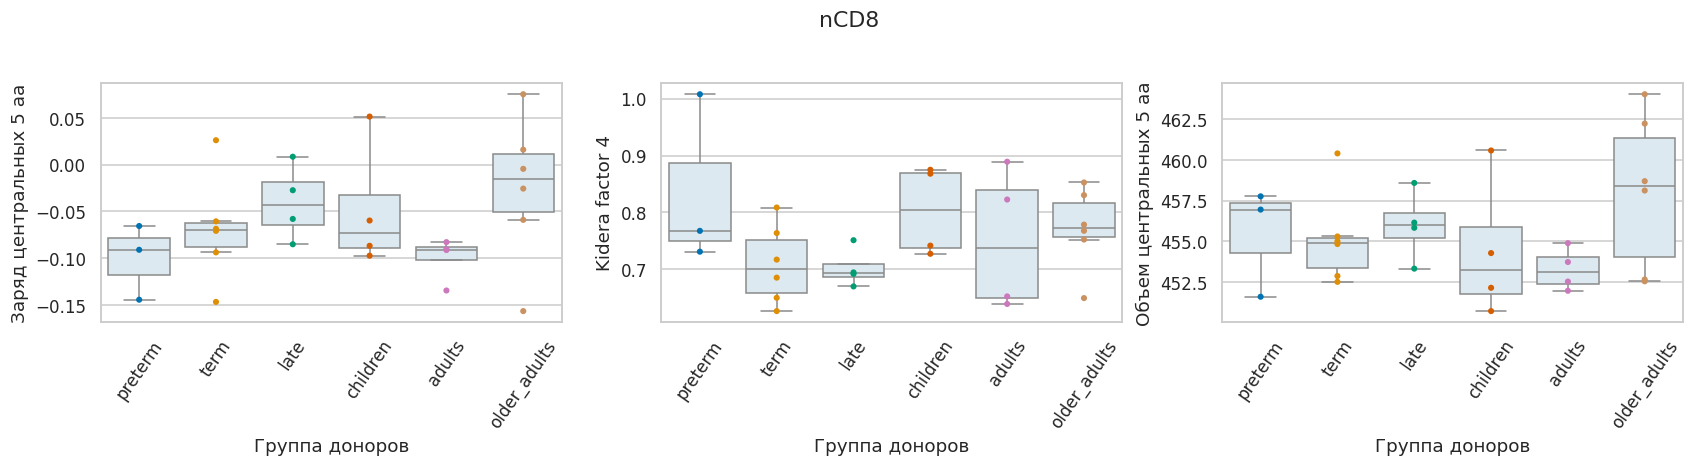

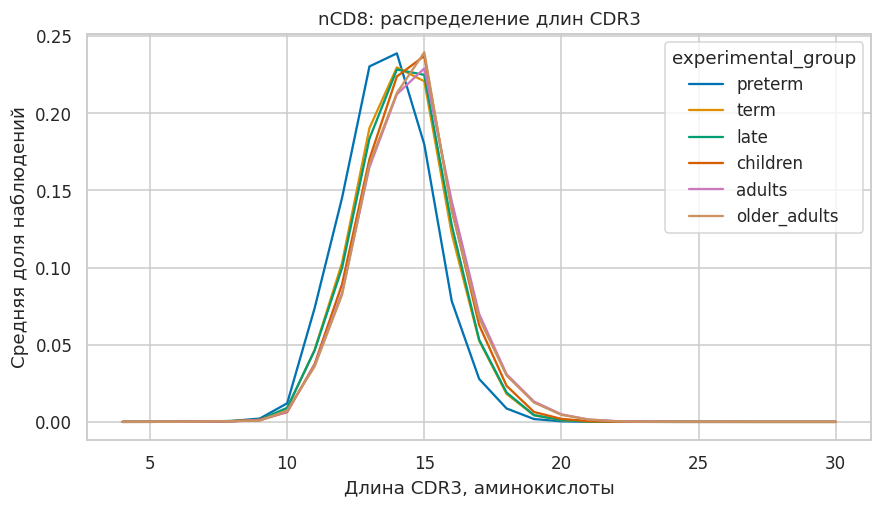

,mean_cdr3aa_len,mean_insert_size,zero_insert_freq
experimental_group,,,
preterm,13.5859,3.2366,0.2681
term,14.1563,5.8334,0.0742
late,14.1850,6.1773,0.0584
children,14.3617,7.0312,0.0244
adults,14.4427,7.3657,0.0234
older_adults,14.4451,7.1161,0.0253


In [ ]:
cdr3_properties = stats.calc_cdr3_properties(SAMPLES, cl_filter=FUNC_FILTER, cpu=CPU, verbose=False)
cdr3_properties["mean_cdr3aa_len"] = cdr3_properties["mean_cdr3nt_len"] / 3
cdr3_properties.to_csv(OUT / "cdr3_properties.csv", index=False)
group_boxes(cdr3_properties, ["mean_cdr3aa_len", "mean_insert_size", "zero_insert_freq"], ["Средняя длина CDR3, aa", "Средняя длина вставок, nt", "Доля CDR3 без вставок"], "02_cdr3_properties")
group_boxes(cdr3_properties, ["cdr3_5_charge", "cdr3_5_kf4", "cdr3_5_volume"], ["Заряд центральных 5 aa", "Kidera factor 4", "Объем центральных 5 aa"], "03_amino_acid_properties")
lengths = stats.cdr3_length_distributions(SAMPLES, cl_filter=FUNC_FILTER, cpu=CPU, count_by_freq=True, seq_type="aa", zero_fill=True, verbose=False)
lengths.to_csv(OUT / "cdr3_lengths.csv", index=False)
lengths_meta = with_metadata(lengths)
length_means = lengths_meta.groupby(["experimental_group", "cdr3_length"], observed=True)["freq"].mean().reset_index()
fig, ax = plt.subplots(figsize=(9.2, 4.8))
sns.lineplot(data=length_means, x="cdr3_length", y="freq", hue="experimental_group", hue_order=GROUPS, palette=PALETTE, ax=ax)
ax.set(xlabel="Длина CDR3, аминокислоты", ylabel="Средняя доля наблюдений", title=f"{SUBSET}: распределение длин CDR3")
show_figure(fig, "04_cdr3_length_distribution")
display(with_metadata(cdr3_properties).groupby("experimental_group", observed=True)[["mean_cdr3aa_len", "mean_insert_size", "zero_insert_freq"]].median().round(4))

### Использование V- и J-генов

Считаю частоты сегментов в продуктивной части каждого репертуара. Для V показываю 20 наиболее используемых генов по средней частоте, полная таблица всех V-генов сохраняется в CSV. J-гены показаны полностью. Частоты сначала считаются для каждого донора, затем усредняются по группе.

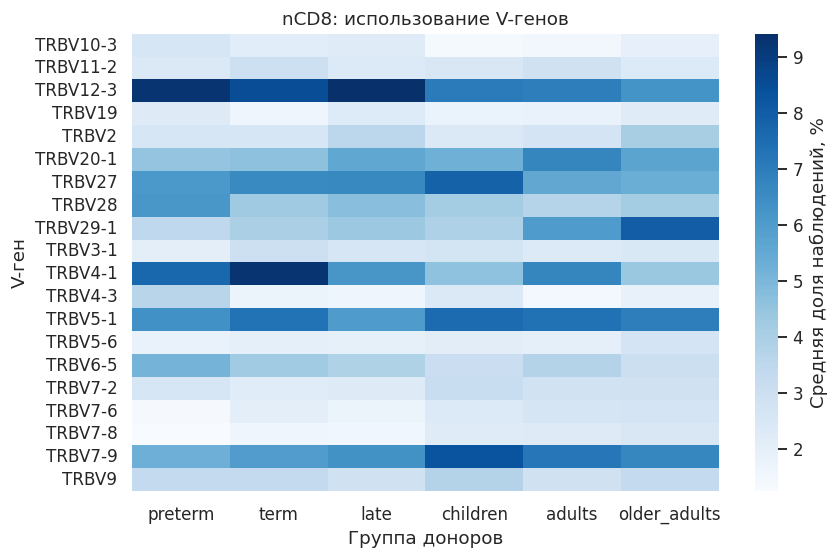

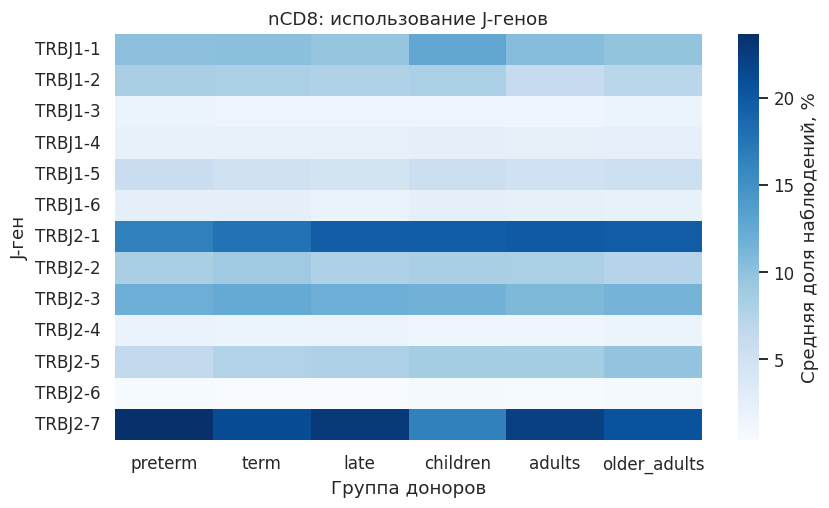

In [ ]:
v_usage = stats.calc_segment_usage(SAMPLES, segment="v", cl_filter=FUNC_FILTER, cpu=CPU, verbose=False)
j_usage = stats.calc_segment_usage(SAMPLES, segment="j", cl_filter=FUNC_FILTER, cpu=CPU, verbose=False)
v_usage.to_csv(OUT / "v_usage.csv", index=False)
j_usage.to_csv(OUT / "j_usage.csv", index=False)
usage_heatmap(v_usage, "v", "05_v_usage_top20", top=20)
usage_heatmap(j_usage, "j", "06_j_usage")

### Конвергенция

Метрика показывает, сколько разных нуклеотидных CDR3 в среднем соответствует одной аминокислотной CDR3. Отдельно учитываются совпадения с тем же V-геном и с теми же V/J. Для сравнения использую равную глубину 5000. Более высокое значение согласуется с более выраженной конвергентной рекомбинацией, но не доказывает общую антигенную специфичность.

Calcultating stats for original clonosets
_________________________________________
WARNING! Following samples have NaN downsample counts ('umi_func'): o3_nCD8_TRB_1, UCB13_nCD8_TRB_1, o1_nCD8_TRB_1, a5_nCD8_TRB_1, UCB4_nCD8_TRB_1, UCB12_nCD8_TRB_1, o2_nCD8_TRB_1, UCB7_nCD8_TRB_1, a12_nCD8_TRB_1, UCB8_nCD8_TRB_1, a4_nCD8_TRB_1, UCB11_nCD8_TRB_1, UCB5_nCD8_TRB_1, UCB3_nCD8_TRB_1, UCB10_nCD8_TRB_1, c5_nCD8_TRB_1, UCB9_nCD8_TRB_1, o6_nCD8_TRB_1, o4_nCD8_TRB_1, c1_nCD8_TRB_1, UCB2_nCD8_TRB_1, UCB6_nCD8_TRB_1, a6_nCD8_TRB_1, o7_nCD8_TRB_1, UCB1_nCD8_TRB_2, c2_nCD8_TRB_1, c4_nCD8_TRB_1
These samples will be counted by reads instead
Out[0]: 
           sample_id chain  convergence  ...  experimental_group  donor_id subset
0      o3_nCD8_TRB_1   TRB     1.001799  ...        older_adults        o3   nCD8
1   UCB13_nCD8_TRB_1   TRB     1.014554  ...                term     UCB13   nCD8
2      o1_nCD8_TRB_1   TRB     1.003785  ...        older_adults        o1   nCD8
3      a5_nCD8_TRB_1   TRB   

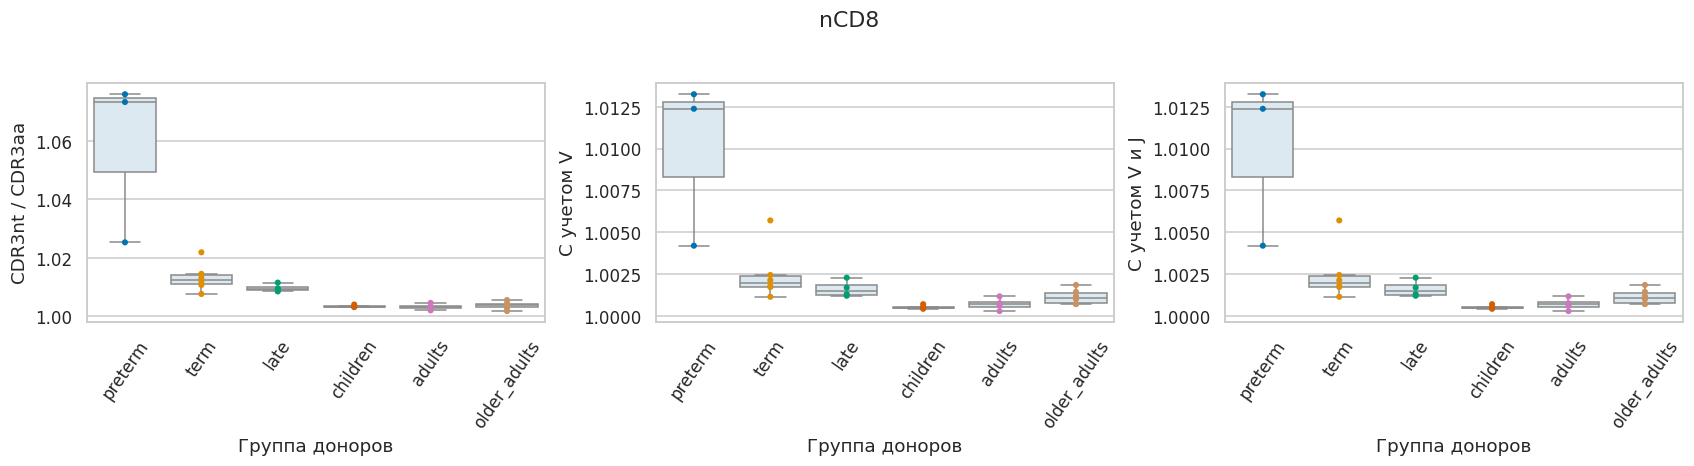

In [ ]:
convergence = stats.calc_convergence(SAMPLES, cl_filter=MC_FILTER, seed=42, iterations=3, cpu=CPU, verbose=False)
convergence.to_csv(OUT / "convergence.csv", index=False)
group_boxes(convergence, ["convergence", "convergence_v", "convergence_vj"], ["CDR3nt / CDR3aa", "С учетом V", "С учетом V и J"], "07_convergence")

### Альфа-разнообразие и чувствительность к глубине

`diversity` - число наблюдаемых клонотипов, Shannon учитывает богатство и равномерность, `clonality = 1 - нормированный Shannon`. Chao1 оценивает богатство с учетом редких клонотипов и может быть нестабильным. Выполняю три воспроизводимых повтора субсэмплирования; в таблицах показаны их средние значения. Для повторов seed задается в функции расчета, а seed внутри копии фильтра отключен: иначе эта версия repseq заново фиксирует одну и ту же выборку на каждом повторе.

Calcultating stats for original clonosets
_________________________________________
WARNING! Following samples have NaN downsample counts ('umi_func'): o3_nCD8_TRB_1, UCB13_nCD8_TRB_1, o1_nCD8_TRB_1, a5_nCD8_TRB_1, UCB4_nCD8_TRB_1, UCB12_nCD8_TRB_1, o2_nCD8_TRB_1, UCB7_nCD8_TRB_1, a12_nCD8_TRB_1, UCB8_nCD8_TRB_1, a4_nCD8_TRB_1, UCB11_nCD8_TRB_1, UCB5_nCD8_TRB_1, UCB3_nCD8_TRB_1, UCB10_nCD8_TRB_1, c5_nCD8_TRB_1, UCB9_nCD8_TRB_1, o6_nCD8_TRB_1, o4_nCD8_TRB_1, c1_nCD8_TRB_1, UCB2_nCD8_TRB_1, UCB6_nCD8_TRB_1, a6_nCD8_TRB_1, o7_nCD8_TRB_1, UCB1_nCD8_TRB_2, c2_nCD8_TRB_1, c4_nCD8_TRB_1
These samples will be counted by reads instead
Calcultating stats for original clonosets
_________________________________________
WARNING! Following samples have NaN downsample counts ('umi_func'): o3_nCD8_TRB_1, UCB13_nCD8_TRB_1, o1_nCD8_TRB_1, a5_nCD8_TRB_1, UCB4_nCD8_TRB_1, UCB12_nCD8_TRB_1, o2_nCD8_TRB_1, UCB7_nCD8_TRB_1, a12_nCD8_TRB_1, UCB8_nCD8_TRB_1, a4_nCD8_TRB_1, UCB11_nCD8_TRB_1, UCB5_nCD8_TRB_1, U

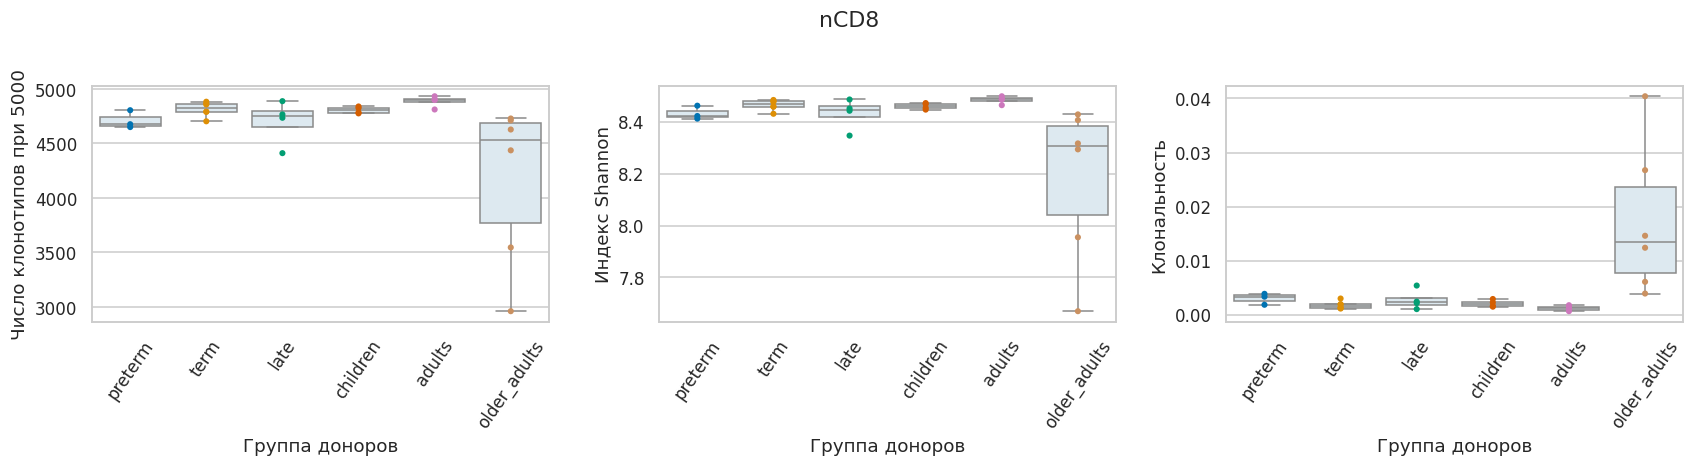

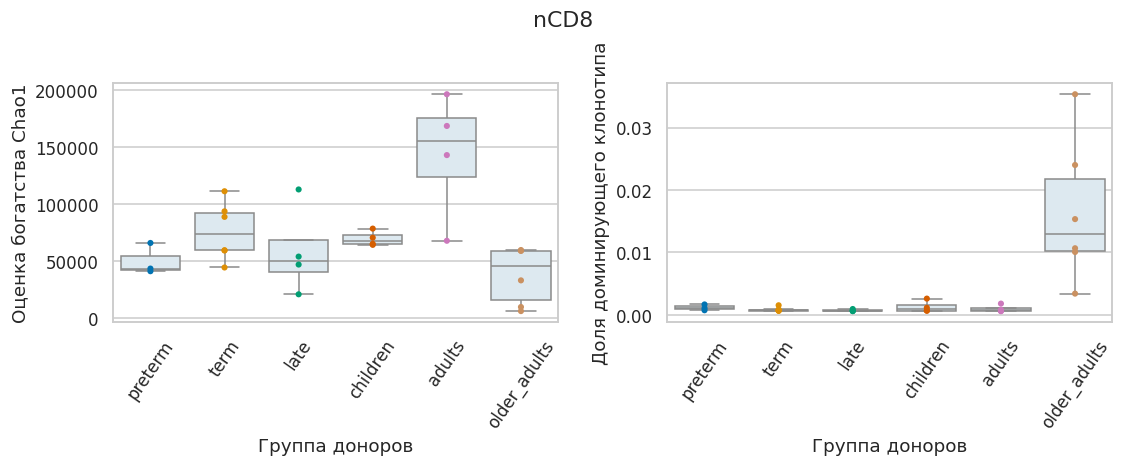

,diversity,shannon_wiener,clonality,chao1,berger_parker
experimental_group,,,,,
preterm,4675.6667,8.4220,0.0033,43237.1156,0.0011
term,4823.8333,8.4677,0.0016,73961.0710,0.0007
late,4750.0000,8.4466,0.0023,50262.2934,0.0006
children,4803.6667,8.4608,0.0019,67630.3553,0.0009
adults,4898.8333,8.4864,0.0012,155626.0860,0.0007
older_adults,4531.5000,8.3050,0.0135,45844.0191,0.0130


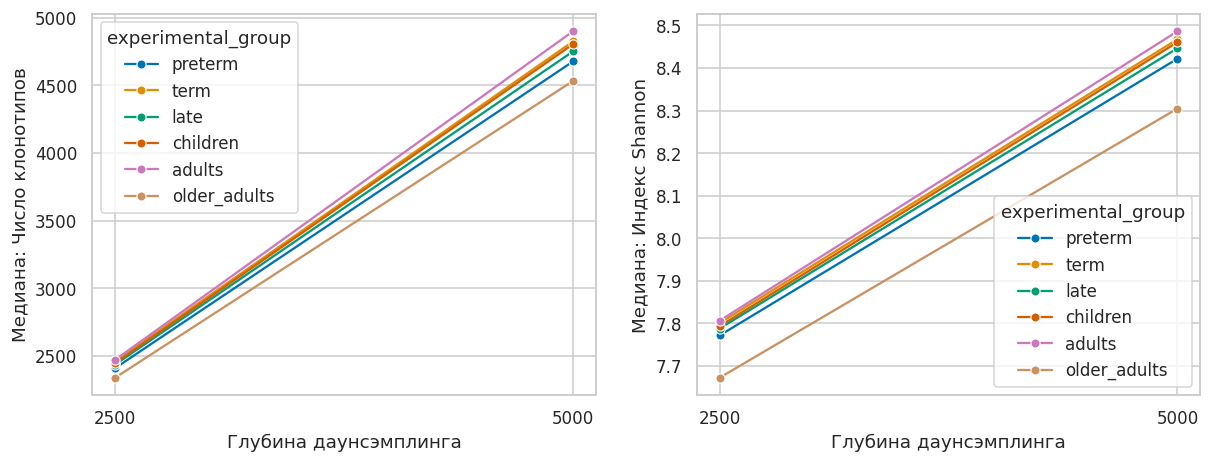

,Метрика,Корреляция рангов между глубинами
0,diversity,0.993284
1,shannon_wiener,0.993895
2,clonality,0.993895


In [ ]:
diversity = stats.calc_diversity_stats(SAMPLES, cl_filter=MC_FILTER, seed=123, iterations=3, drop_small_samples=False, cpu=CPU, verbose=False)
diversity_alt = stats.calc_diversity_stats(SAMPLES, cl_filter=MC_ALT_FILTER, seed=123, iterations=3, drop_small_samples=False, cpu=CPU, verbose=False)
diversity.to_csv(OUT / "diversity_5000.csv", index=False)
diversity_alt.to_csv(OUT / "diversity_2500.csv", index=False)
group_boxes(diversity, ["diversity", "shannon_wiener", "clonality"], ["Число клонотипов при 5000", "Индекс Shannon", "Клональность"], "08_alpha_diversity")
group_boxes(diversity, ["chao1", "berger_parker"], ["Оценка богатства Chao1", "Доля доминирующего клонотипа"], "09_chao1_dominance")
summary = with_metadata(diversity).groupby("experimental_group", observed=True)[["diversity", "shannon_wiener", "clonality", "chao1", "berger_parker"]].median()
display(summary.round(4))
sensitivity = pd.concat([with_metadata(diversity).assign(depth=DEPTH), with_metadata(diversity_alt).assign(depth=ALT_DEPTH)], ignore_index=True)
sensitivity.to_csv(OUT / "sensitivity.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric, label in zip(axes, ["diversity", "shannon_wiener"], ["Число клонотипов", "Индекс Shannon"]):
    grouped = sensitivity.groupby(["experimental_group", "depth"], observed=True)[metric].median().reset_index()
    sns.lineplot(data=grouped, x="depth", y=metric, hue="experimental_group", hue_order=GROUPS, marker="o", palette=PALETTE, ax=ax)
    ax.set(xlabel="Глубина даунсэмплинга", ylabel=f"Медиана: {label}", xticks=[ALT_DEPTH, DEPTH])
show_figure(fig, "10_sensitivity")
stability = diversity[["sample_id", "diversity", "shannon_wiener", "clonality"]].merge(diversity_alt[["sample_id", "diversity", "shannon_wiener", "clonality"]], on="sample_id", suffixes=("_5000", "_2500"), validate="one_to_one")
display(pd.DataFrame({"Метрика": ["diversity", "shannon_wiener", "clonality"], "Корреляция рангов между глубинами": [stability[f"{m}_5000"].corr(stability[f"{m}_2500"], method="spearman") for m in ["diversity", "shannon_wiener", "clonality"]]}))

### Rarefaction

Кривая показывает, сколько разных клонотипов ожидается при заданном числе наблюдений. Растущая кривая без плато означает неполное покрытие репертуара. Образцы сравниваются при одной и той же глубине, а не по конечным точкам кривых разной длины.

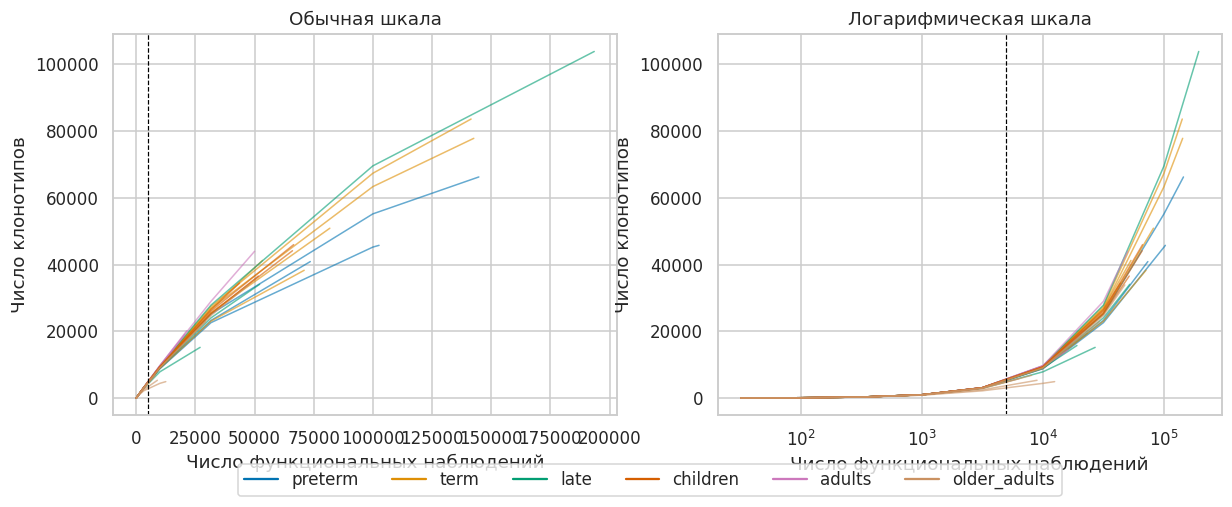

In [ ]:
rarefaction = stats.calc_rarefaction_curve(SAMPLES, cl_filter=FUNC_FILTER, seed=100, iterations=3, cpu=CPU, verbose=False)
rarefaction.to_csv(OUT / "rarefaction.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, log in zip(axes, [False, True]):
    for sample_id, frame in with_metadata(rarefaction).groupby("sample_id", observed=True):
        group = str(frame["experimental_group"].iloc[0])
        frame = frame.sort_values("rarefaction_depth")
        ax.plot(frame["rarefaction_depth"], frame["diversity"], color=PALETTE[group], alpha=0.6, linewidth=1)
    if log:
        ax.set_xscale("log")
    ax.axvline(DEPTH, color="black", ls="--", lw=0.8)
    ax.set(xlabel="Число функциональных наблюдений", ylabel="Число клонотипов", title="Логарифмическая шкала" if log else "Обычная шкала")
handles = [matplotlib.lines.Line2D([0], [0], color=PALETTE[g], label=g) for g in GROUPS]
fig.legend(handles=handles, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.07))
show_figure(fig, "11_rarefaction")

### Бета-разнообразие: F2 и MDS

Совпадение определяется по CDR3aa и V-гену (`aaV`). F2 - сходство с учетом частот, а не расстояние. Отдельно вычисляю F2 для каждой клеточной популяции. Координаты MDS условные, расстояния между точками отражают преобразованное сходство. Видимая группировка без статистической проверки не означает значимость. Попарные сравнения не являются независимыми наблюдениями.

Intersecting clones in clonosets
--------------------------------------------------
Overlap type: aaV
Reading clonosets |##################################################| 27/27 sample(s) processed
Using 2 cores
Intersecting clonosets |##################################################| 351/351 pairs processed


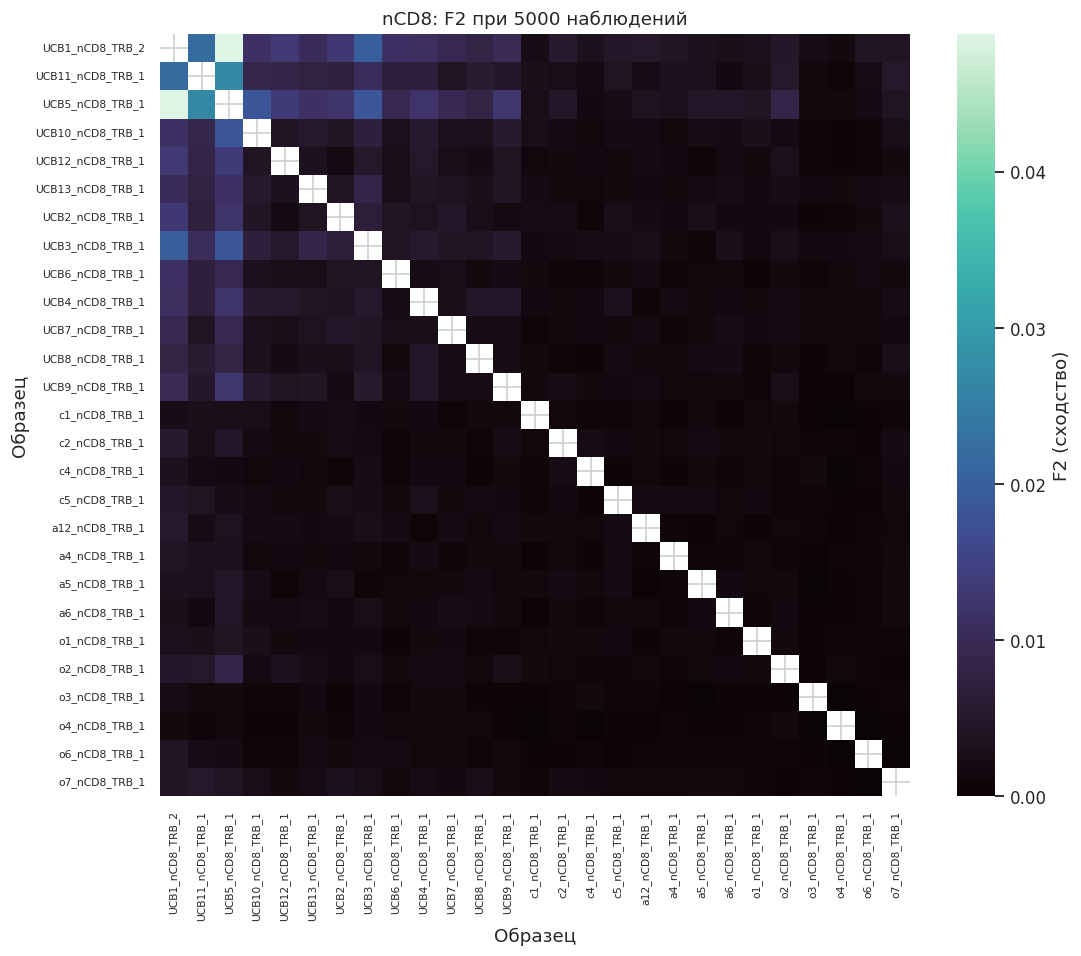

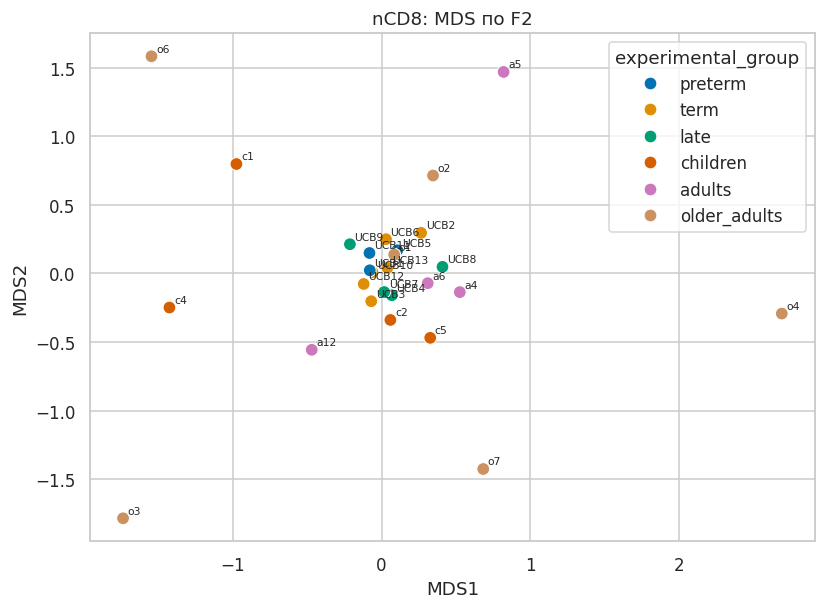

,count,median
group1,,
preterm,3,0.02683
term,15,0.00411
late,6,0.00249
children,6,0.00084
adults,6,0.00070
older_adults,15,0.00055


In [ ]:
f2 = beta.metrics(SAMPLES, cl_filter=DOWN_FILTER, overlap_type="aaV", metrics="f2", cpu=CPU)
f2.to_csv(OUT / "f2.csv")
assert np.allclose(f2.to_numpy(), f2.to_numpy().T)
assert np.allclose(np.diag(f2), 1)
sample_order = SAMPLES.sort_values(["experimental_group", "donor_id"])["sample_id"].tolist()
fig, ax = plt.subplots(figsize=(11, 9))
mask = np.eye(len(f2), dtype=bool)
sns.heatmap(f2.loc[sample_order, sample_order], mask=mask, cmap="mako", ax=ax, cbar_kws={"label": "F2 (сходство)"})
ax.set(title=f"{SUBSET}: F2 при 5000 наблюдений", xlabel="Образец", ylabel="Образец")
ax.tick_params(labelsize=7)
show_figure(fig, "12_f2_heatmap")
mds = beta.mds(f2)
mds.to_csv(OUT / "mds.csv", index=False)
mds_meta = with_metadata(mds)
fig, ax = plt.subplots(figsize=(8.5, 6))
sns.scatterplot(data=mds_meta, x="MDS1", y="MDS2", hue="experimental_group", hue_order=GROUPS, palette=PALETTE, s=70, ax=ax)
for row in mds_meta.itertuples():
    ax.annotate(row.sample_id.split("_")[0], (row.MDS1, row.MDS2), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(title=f"{SUBSET}: MDS по F2")
show_figure(fig, "13_mds")
pairs = []
groups_by_sample = SAMPLES.set_index("sample_id")["experimental_group"].astype(str)
for i, first in enumerate(f2.index):
    for second in f2.index[i + 1:]:
        group1, group2 = groups_by_sample[first], groups_by_sample[second]
        pairs.append({"sample1": first, "sample2": second, "group1": group1, "group2": group2, "f2": f2.loc[first, second], "same_group": group1 == group2})
pair_table = pd.DataFrame(pairs)
pair_table.to_csv(OUT / "f2_pairs.csv", index=False)
display(pair_table.loc[pair_table["same_group"]].groupby("group1")["f2"].agg(["count", "median"]).reindex(GROUPS).round(5))
RESULTS[SUBSET] = {"clonoset_stats": clonoset_stats, "cdr3_properties": cdr3_properties, "diversity": diversity, "diversity_alt": diversity_alt, "convergence": convergence, "f2": f2, "mds": mds}

### Интерпретация nCD8

Для nCD8 проанализировано 27 образцов из шести групп. Минимальная функциональная глубина равна 6368, поэтому даунсэмплирование до 5000 сохранило все образцы. Подсчитанные размеры продуктивных клоносетов и наблюдений совпали с метаданными архива.

У недоношенных детей медиана средней длины CDR3 составила 13,59 aa, а у взрослых - 14,44 aa. Медиана средней длины вставок составила 3,24 и 7,37 nt соответственно. Доля CDR3 без вставок у недоношенных была 26,81%, у взрослых - 2,34%. Таким образом, ранние репертуары содержат более короткие CDR3 с меньшим количеством вставок. Это повторяет основное наблюдение семинара для другой клеточной популяции.

Для пяти центральных аминокислот CDR3 медианы показателя заряда составили -0,091 у недоношенных и -0,091 у взрослых; KF4 - 0,768 и 0,738, показателя объема - 456,9 и 453,1. Это характеристики аминокислотного состава в шкалах repseq. По ним нельзя определять заряд целого рецептора, силу связывания или антигенную специфичность. Анализ фиксированного центрального участка уменьшает прямое влияние различной длины CDR3.

Среди наиболее используемых V-генов в среднем по всем образцам - TRBV12-3, TRBV5-1, TRBV7-9; среди J-генов - TRBJ2-7, TRBJ2-1. На heatmap видны различия профилей между группами. При этом наиболее частый ген сам по себе не является доказательством специфического ответа на определенный антиген. Чтобы говорить о значимости отдельных различий V/J, нужна отдельная статистическая проверка с учетом множественных сравнений.

При одинаковой глубине 5000 медиана числа клонотипов у недоношенных составила 4675,7, у взрослых - 4898,8, у пожилых - 4531,5. Медианы Shannon в этих группах равны 8,422, 8,486 и 8,305. Разнообразие не следует трактовать как автоматически и строго монотонную функцию возраста: смотрю на все группы и разброс отдельных доноров.

В CD8 у пожилых Shannon ниже, а клональность выше, чем у взрослых: медиана клональности 0,0135 против 0,0012. На графике заметен большой разброс пожилых доноров. Это согласуется с большей неравномерностью частот и расширением отдельных клонов в части образцов, но не доказывает влияние возраста без учета остальных факторов.

Корреляция рангов образцов между глубинами 2500 и 5000 составила 0,993 для числа клонотипов и 0,994 для Shannon. При меньшей глубине ожидаемо обнаруживается меньше разных клонотипов. Эти корреляции показывают устойчивость ранжирования к выбранным двум глубинам, но не заменяют проверку биологических гипотез и не подтверждают устойчивость при любых настройках.

Конвергенция CDR3aa у недоношенных имела групповую медиану 1,0733, у взрослых - 1,0032. Она описывает соотношение разных нуклеотидных и аминокислотных вариантов, а не число B/T-клеточных линий происхождения.

На последнем участке rarefaction медианный прирост составил 0,570 нового клонотипа на одно дополнительное наблюдение. Кривые продолжают расти; полного насыщения секвенированием не достигнуто. Поэтому число найденных клонотипов не равно всему разнообразию, присутствующему у донора.

Наибольшая медиана внутригруппового F2 получилась в группе preterm: 0,02683. Для preterm она составила 0,02683, для adults - 0,00070. Это описательная характеристика сходства по aaV. Более высокое сходство ранних репертуаров согласуется с большей долей повторяющихся вариантов CDR3, но само по себе не устанавливает механизм их образования. Внутригрупповые пары не независимы, поэтому их количество нельзя использовать как число биологических повторов. На MDS образцы пуповинной крови располагаются сравнительно близко, а среди более старших доноров есть удаленные точки; полного разделения всех возрастных групп нет. MDS носит описательный характер. Нельзя приписывать отдельному кластеру общую антигенную специфичность по одному только расположению на графике.

## 6. Сопоставление CD4 и CD8

Обе популяции сравниваю при глубине 5000. Это разные клеточные популяции, поэтому возрастной анализ проводится отдельно внутри каждой. Группы имеют разный размер. В периферической крови CD4 обозначены как `mnCD4` и отсортированы с CD31-, в отличие от UCB; различия нельзя объяснять только возрастом. Все выводы описательные: формальная проверка гипотез и коррекция множественных сравнений здесь не проводятся.

In [ ]:
comparison_rows = []
for subset, result in RESULTS.items():
    joined = with_metadata(result["diversity"])
    props = with_metadata(result["cdr3_properties"])
    for group in GROUPS:
        frame = joined.loc[joined["experimental_group"].eq(group)]
        prop = props.loc[props["experimental_group"].eq(group)]
        comparison_rows.append({"population": subset, "group": group, "n": len(frame), "median_cdr3aa": prop["mean_cdr3aa_len"].median(), "median_insert_nt": prop["mean_insert_size"].median(), "median_diversity_5000": frame["diversity"].median(), "median_shannon_5000": frame["shannon_wiener"].median(), "median_clonality_5000": frame["clonality"].median()})
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(PROJECT_ROOT / "outputs" / "tcr" / "CD4_CD8_summary.csv", index=False)
display(comparison.round(4))
provenance = {"python": platform.python_version(), "packages": {name: version(name) for name in ["repseq", "numpy", "pandas", "scipy", "matplotlib", "seaborn"]}, "depth": DEPTH, "alternative_depth": ALT_DEPTH, "filter_seed": SEED, "diversity_seed": 123, "iterations": 3, "overlap_type": "aaV", "subsets": ["nCD4", "nCD8"]}
(PROJECT_ROOT / "outputs" / "tcr" / "provenance.json").write_text(json.dumps(provenance, ensure_ascii=False, indent=2), encoding="utf-8")

Out[0]: 369


,population,group,n,median_cdr3aa,median_insert_nt,median_diversity_5000,median_shannon_5000,median_clonality_5000
0,nCD4,preterm,3,13.5990,3.4977,4729.6667,8.4389,0.0027
1,nCD4,term,6,14.1588,6.1780,4823.8333,8.4676,0.0016
2,nCD4,late,4,14.2450,6.2539,4768.8333,8.4522,0.0021
3,nCD4,children,4,14.3553,7.1318,4544.6667,8.3834,0.0044
4,nCD4,adults,9,14.5646,7.4804,4722.6667,8.4389,0.0025
5,nCD4,older_adults,4,14.4876,7.2964,4845.8333,8.4739,0.0014
6,nCD8,preterm,3,13.5859,3.2366,4675.6667,8.4220,0.0033
7,nCD8,term,6,14.1563,5.8334,4823.8333,8.4677,0.0016
8,nCD8,late,4,14.1850,6.1773,4750.0000,8.4466,0.0023
9,nCD8,children,4,14.3617,7.0312,4803.6667,8.4608,0.0019
